In [1]:
import pathlib
import sys
module_dir = pathlib.Path("").parent.resolve()
root_dir = module_dir.parent
asvlite_wrapper_dir = root_dir.joinpath("dependency", "ASVLite", "wrapper", "cython")
sys.path.insert(0, str(asvlite_wrapper_dir))

In [2]:
import numpy as np

In [3]:
import math
from shapely.geometry import Point, LineString
from shapely.ops import nearest_points
from sea_surface import py_Sea_surface
from asv import py_Asv_specification, py_Asv
from geometry import py_Coordinates_3D
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = [18, 5]

In [4]:
# Simulation time step size
time_step_size = 40 # milli-sec

In [5]:
def simulate(time_duration, sea_surface, asv):
    '''
    Function to simulate the dynamics of an ASV on a given sea_surface for a given time_duration (sec).
    '''
    positions = [] # store asv positions
    attitudes = [] # store asv attitudes
    accelerations = [] # store asv accelerations
    elevations= [] # store sea surface elivations
    # Simulation is performed for the duration defined above with a time step size of 40 milli sec.
    for i in range(int(time_duration * 1000.0 /time_step_size)):  
        time = i * time_step_size/1000.0
        # Record the position, attitude and elevation for ploting
        position = asv.py_get_position_cog() # Get current position of the ASV
        positions.append(position)
        attitude = asv.py_get_attitude() # Get current attitude of the ASV
        attitudes.append(attitude)
        acceleration = asv.py_get_A()
        accelerations.append(acceleration)
        elevation= sea_surface.py_get_elevation(position, time)
        elevations.append(elevation)
        # Compute asv dynamics
        asv.py_compute_dynamics(time_step_size)
    return(positions, attitudes, accelerations, elevations)

In [6]:
# ASV spec
asv_spec = py_Asv_specification()
asv_spec.L_wl       = 2.1 # m
asv_spec.B_wl       = 0.6 # m
asv_spec.D          = 0.25 # m 
asv_spec.T          = 0.09 # m
asv_spec.max_speed  = 4.0 # m/s
asv_spec.disp       = 0.09 # m3
asv_spec.r_roll     = 0.2 # m
asv_spec.r_pitch    = 0.6 # m
asv_spec.r_yaw      = 0.6 # m
asv_spec.cog        = py_Coordinates_3D(1.05, 0.0, -0.2) # m

In [7]:
# Simulation time in seconds
time_duration = 60 # sec

## Experiment 1 - Sync using sea surface elevations

- asv_1 and asv_2 placed at two different locations.
- Both asvs will collect the sea surface elevations at its location.
- The asvs will then compute the perdominant wave frequency using FFT and will move to a new position to synchronise there heave motions. 
- The new position will be computed from the intial position moving along the direction of propagation of the predominant swell.

In [8]:
# Sea surface
wave_rand_seed = 1
count_component_waves = 21
wave_hs = 1.2 # Significant wave height in m
wave_dp = math.pi/6 # wave direction of propagation 45 deg N
sea_surface = py_Sea_surface(wave_hs, wave_dp, wave_rand_seed)

In [9]:
# Start position and attitude
start_attitude = py_Coordinates_3D(0.0, 0.0, 0.0) # Both ASVs will have the same initial attitude
position_1 = py_Coordinates_3D(100.0, 100.0)
position_2 = py_Coordinates_3D(250.0, 250.0)

In [10]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_halt_surge_and_sway(True)
asv_2.py_set_halt_surge_and_sway(True)

In [11]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

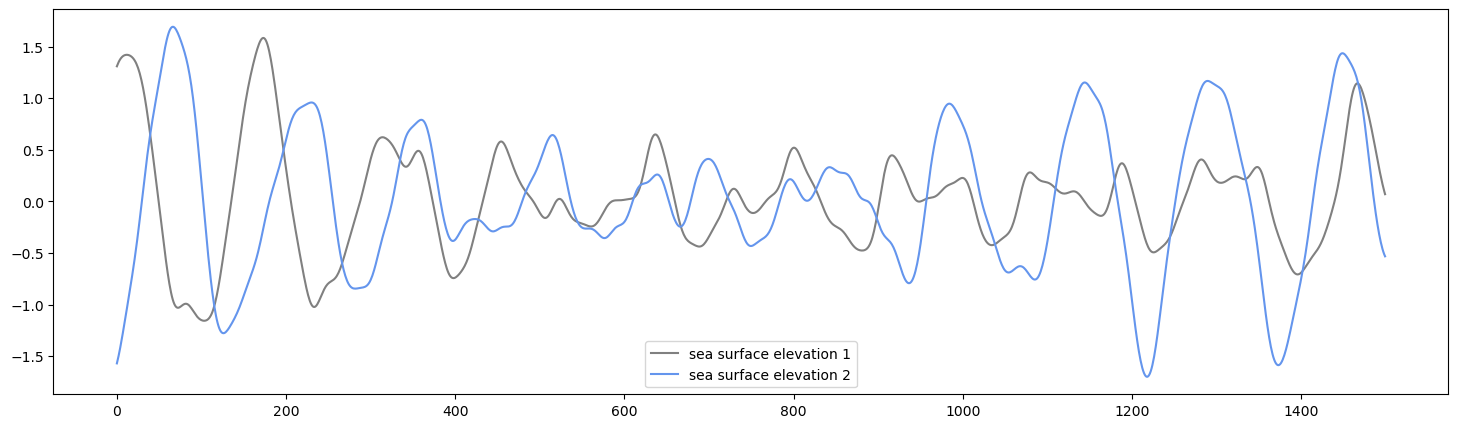

In [12]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

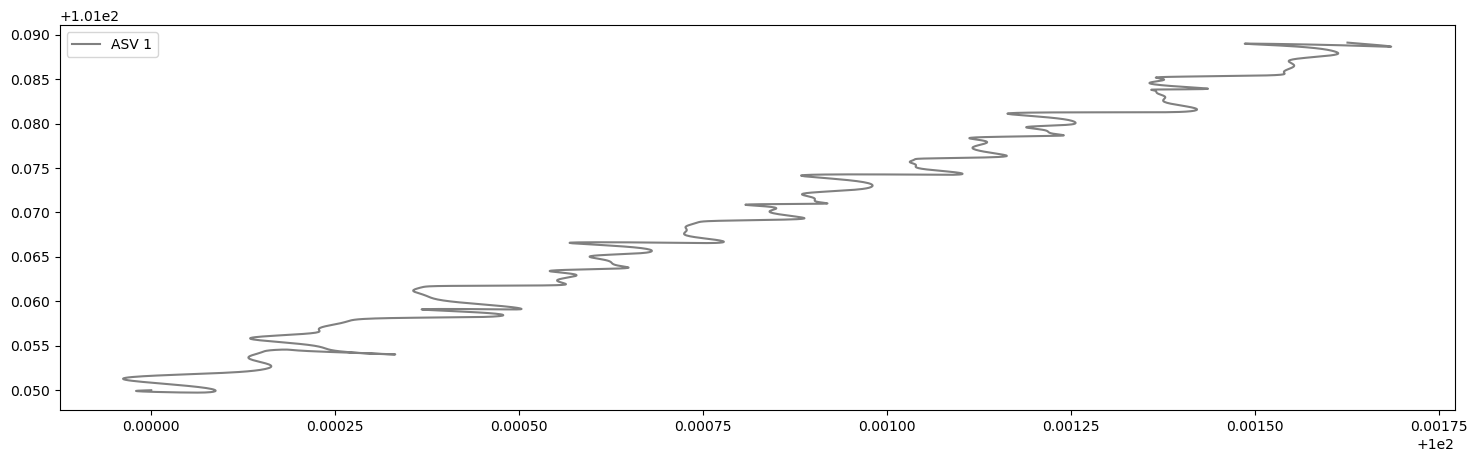

In [13]:
# Plot the ASVs paths. It should not be moving. 
plt.plot([position.x for position in positions_1], [position.y for position in positions_1], label="ASV 1", color="grey")
plt.legend()

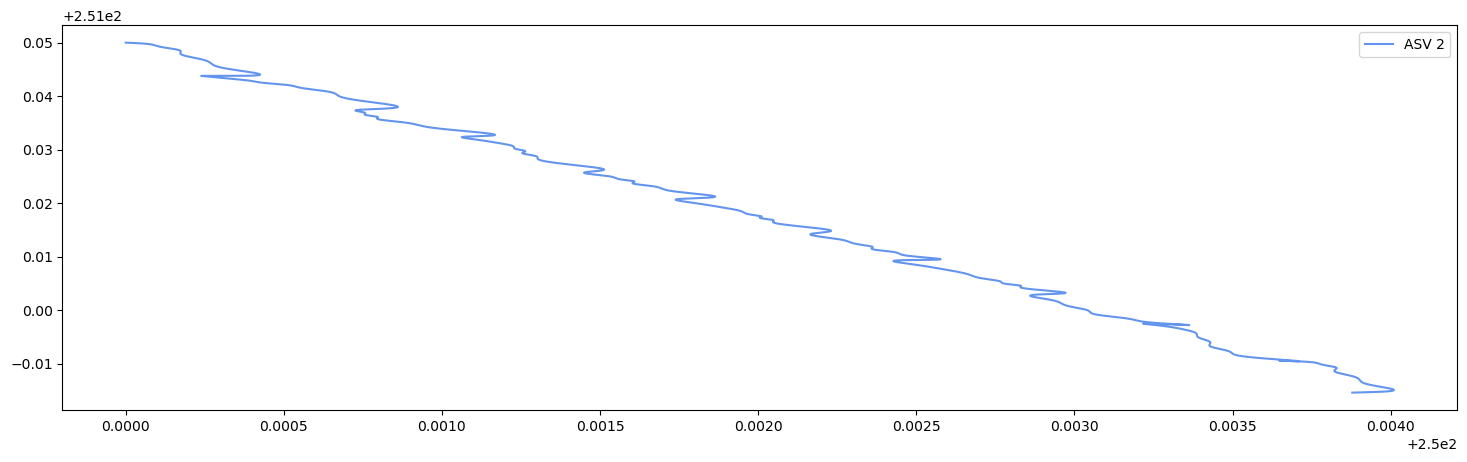

In [14]:
# Plot the ASVs paths. It should not be moving. 
plt.plot([position.x for position in positions_2], [position.y for position in positions_2], label="ASV 2", color="cornflowerblue")
plt.legend()

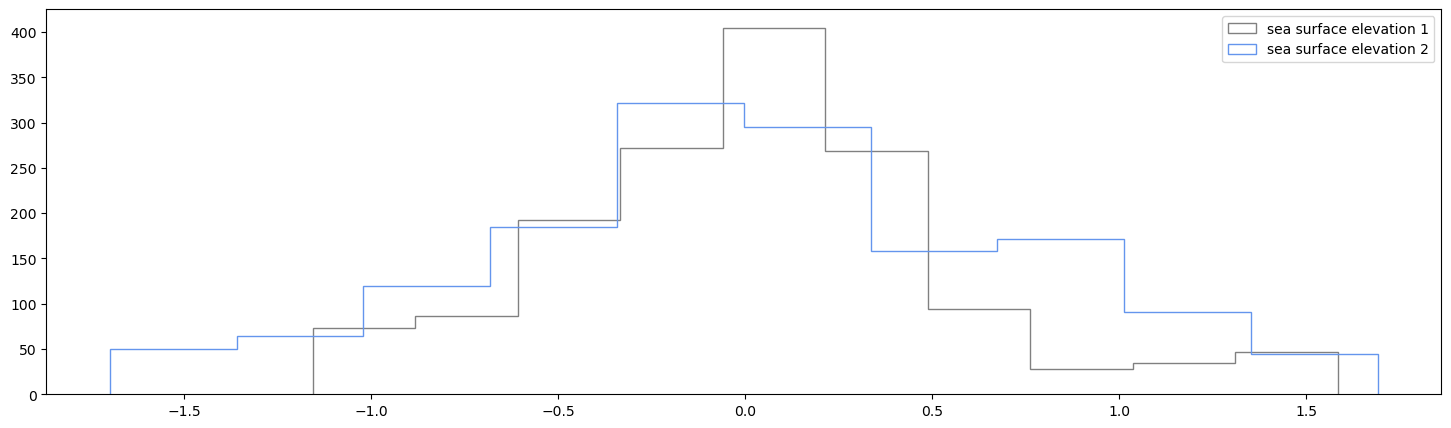

In [15]:
plt.hist(elevations_1, histtype=u'step', label="sea surface elevation 1", color="grey")
plt.hist(elevations_2, histtype=u'step', label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

In [16]:
# # Make a normalised plot
# trimmer_size = 100
# # trimmer_size = int((5 * 60)/(time_step_size/1000))
# np_elevations = np.array(elevations[trimmer_size:])
# np_heave_positions = np.array([position.z  for position  in positions[trimmer_size:]])
# def normalise_vector(vector):
#     vector = vector - np.mean(vector)
#     vector = vector/np.max(np.abs(vector))
#     return vector

# normalised_elevations = normalise_vector(np_elevations)
# normalised_heave_positions = normalise_vector(np_heave_positions)


# # plot
# plt.plot(normalised_elevations, label="sea surface elevation", color="skyblue")
# plt.plot(normalised_heave_positions, label="heave positions", color="orange")
# plt.legend()


### Fast Fourier Transform

In [17]:
def fast_fourier_transform(vector):
    n = len(vector)
    fhat = np.fft.fft(vector)
    PSD = fhat * np.conj(fhat) # Power Spectral Density (Power Spectrum)
    freq = np.fft.fftfreq(len(vector), d=time_step_size/1000)
    i_max = np.argmax(PSD) # index corresponding to max power
    L = np.arange(1, np.floor(n/2), dtype="int")
    return(L, fhat, freq, PSD, i_max)

In [18]:
L_1, fhat_1, freq_1, PSD_1, i_max_1 = fast_fourier_transform(elevations_1)
L_2, fhat_2, freq_2, PSD_2, i_max_2 = fast_fourier_transform(elevations_2)

/home/toby/micromamba/envs/seasyncsquad/lib/python3.11/site-packages/matplotlib/cbook/__init__.py:1340: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


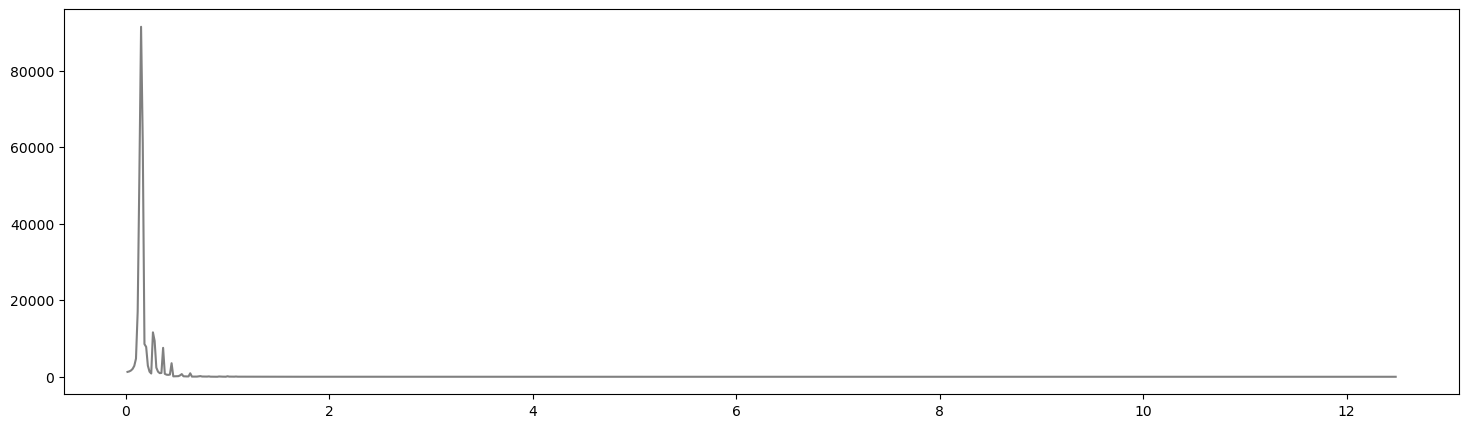

In [19]:
plt.plot(freq_1[L_1], PSD_1[L_1], color="grey")

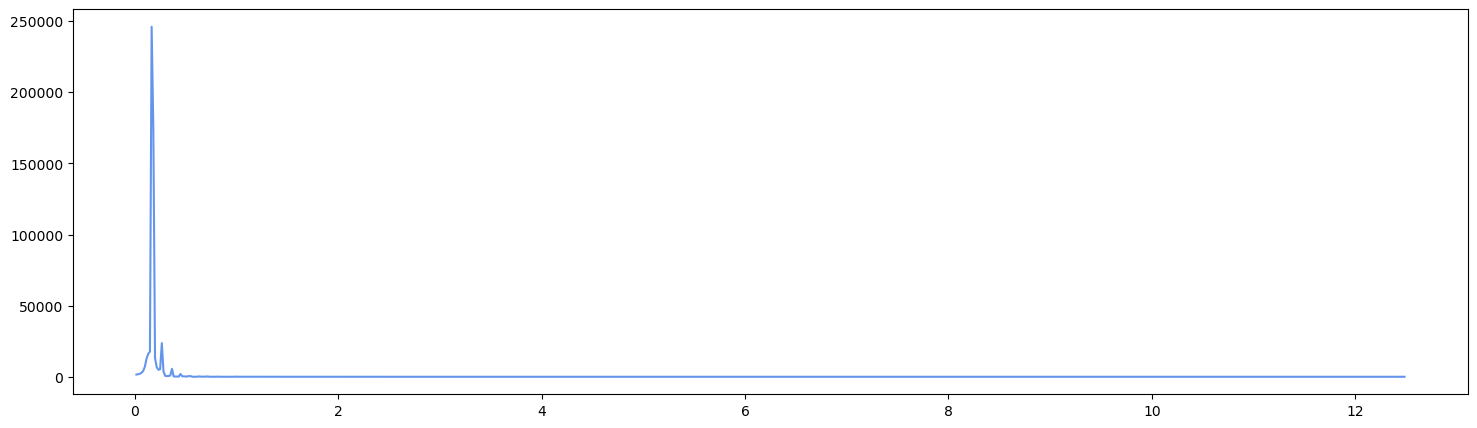

In [20]:
plt.plot(freq_2[L_2], PSD_2[L_2], color="cornflowerblue")

In [21]:
f_max_1 = abs(freq_1[i_max_1])
f_max_2 = abs(freq_2[i_max_2])
print("Peak freq for ASV_1 = ", f_max_1)
print("Peak freq for ASV_2 = ", f_max_2)

Peak freq for ASV_1 =  0.15
Peak freq for ASV_2 =  0.16666666666666666


In [22]:
sea_surface.py_get_peak_spectral_frequency()

0.18263810872998018

### Find the nearest positions to move to

In [23]:
def get_new_position(angle, current_position, freq):
    p_r0 = Point(0, 0) # Original reference point
    # Create a reference line
    len = 1000000000000 # length of a very long line
    p_r1 = Point(-len*math.sin(angle), -len*math.cos(angle))
    p_r2 = Point(len*math.sin(angle), len*math.cos(angle))
    ref_line_0 = LineString([p_r1, p_r2]) # Create the very long line
    # Offset the reference line to pass through the given point
    tolerance = 1/1000.0 # tolerance = 1mm
    p_c = Point(current_position.x, current_position.y)
    d = ref_line_0.distance(p_c)
    ref_line = None # new reference line
    p_0 = None # new refernce point
    if d <= tolerance:
        # The current reference is line is already passing through the point
        ref_line = ref_line_0
        p_0 = p_r0
    else:
        ref_line_1 = ref_line_0.offset_curve(d) # Offset to one side
        ref_line_2 = ref_line_0.offset_curve(-d) # Offset to the other side
        # Find which of these ref lines pass through the current position
        if(ref_line_1.distance(p_c) <= tolerance):
            ref_line = ref_line_1
        elif(ref_line_2.distance(p_c) <= tolerance):
            ref_line = ref_line_2
        # Find the new reference point on the new reference line
        p_0 = nearest_points(ref_line, p_r0)[0]
    # Distance of the current point from the new reference point
    len_0 = ((p_0.x - p_c.x)**2 + (p_0.y - p_c.y)**2)**0.5
    # Distance of the new reference point from the start point of the new reference line
    len_1 = p_r1.distance(p_0)
    # Find the nearest new point to move to 
    wave_length = 9.81/(2.0* np.pi * freq**2) # Get the wave length from the frequency
    len_2 = math.floor(len_0/wave_length) * wave_length # Find the lenth on the line that is a multiple of the wave length
    p_new = ref_line.interpolate(len_1+len_2)
    return py_Coordinates_3D(p_new.x, p_new.y)

In [24]:
new_position_1 = get_new_position(wave_dp, position_1, f_max_1)
print("py_Coordinate_3D({}, {})".format(new_position_1.x, new_position_1.y))

new_position_2 = get_new_position(wave_dp, position_2, f_max_2)
print("py_Coordinate_3D({}, {})".format(new_position_2.x, new_position_2.y))

py_Coordinate_3D(66.39453125, 41.7935791015625)
py_Coordinate_3D(247.8682861328125, 246.3077392578125)


### Simulate with new positions

In [25]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, new_position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, new_position_2, start_attitude)

In [26]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

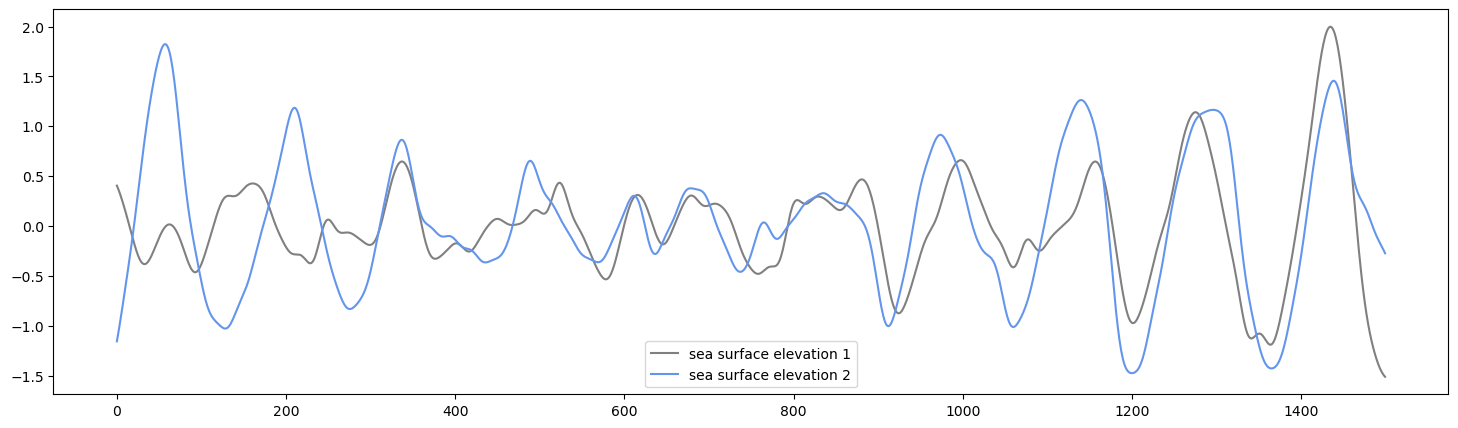

In [27]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

**Further investigation required:**

1. Exp 1 should be to position the vehicle at the along multiple of peak wave frequency along the direction of the predominant wave.
2. When simulating again after moving to the new position, the simulation should not restart, instead should continue from the time the first simulation was stoped.
3. Why are the waves at the two locations having very different amplitudes and peak spectral freq?